# Renewable Electricity Trends

**Author:** Nishant Jha  
**Dataset:** Our World in Data Energy dataset  

This analysis compares renewable electricity in India, Germany, and Brazil from 2000 through 2024. It uses national electricity shares, generation totals, and source shares to describe how the mix changed over time. The fixed period ends in 2024 so each country is compared across the same 25 calendar years; the 2025 observations in the dataset are outside this project scope.

## Setup

The workflow uses Python, Pandas, NumPy, Matplotlib, and Seaborn. The full source file is included in `data/owid_energy.csv`. The focused analysis uses only three countries, five source indicators, and the selected 2000 to 2024 period. The dataset also includes 2025, but that year is excluded to keep the comparison period fixed and make the 25 year trend consistent across countries.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
COUNTRIES = ["India", "Germany", "Brazil"]
START_YEAR = 2000
END_YEAR = 2024
DATA_PATH = Path("data/owid_energy.csv")

## Ingestion

The source is Our World in Data's complete Energy dataset, last updated September 10, 2026. It contains one row per country or region and year, with 19,494 rows and 130 columns. The source combines national energy and electricity data from the Energy Institute, Ember, the United States Energy Information Administration, and historical reconstructions. See the [dataset catalog](https://catalog.ourworldindata.org/energy/owid_energy/) for variable definitions, source notes, and updates.

In [2]:
df = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Dataset shape: {df.shape[0]:,} rows by {df.shape[1]} columns")
df.head()

Dataset shape: 19,494 rows by 130 columns


,country,year,iso_code,population,gdp,bioenergy_electricity_per_capita_kwh,bioenergy_electricity_share_pct,bioenergy_electricity_twh,biofuels_energy_annual_change_pct,biofuels_energy_annual_change_twh,...,total_energy_per_gdp_kwh_per_dollar,total_energy_twh,wind_electricity_per_capita_kwh,wind_electricity_share_pct,wind_electricity_twh,wind_energy_annual_change_pct,wind_energy_annual_change_twh,wind_energy_per_capita_kwh,wind_energy_share_pct,wind_energy_twh
0,ASEAN (Ember),2000,NaN,NaN,NaN,NaN,1.549794,5.87,NaN,NaN,...,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
1,ASEAN (Ember),2001,NaN,NaN,NaN,NaN,1.594707,6.46,NaN,NaN,...,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
2,ASEAN (Ember),2002,NaN,NaN,NaN,NaN,1.528198,6.62,NaN,NaN,...,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
3,ASEAN (Ember),2003,NaN,NaN,NaN,NaN,1.623391,7.44,NaN,NaN,...,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
4,ASEAN (Ember),2004,NaN,NaN,NaN,NaN,1.689455,8.39,NaN,NaN,...,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN


## Cleaning

Two small cleaning functions standardize the field labels and create the analysis table. The first makes column labels consistent even if a future source file includes spaces or mixed capitalization. The second keeps only the selected countries and years, converts the fields used in the plots to numeric values, removes duplicate country and year rows, and drops records without the main renewable share measure. No missing values are filled in because an estimated value could make a trend appear more complete than the source supports. All 75 country year records in the selected period have the required measures.

In [3]:
def clean_column_names(frame):
    """Return a copy with trimmed, lowercase, underscore separated column names."""
    cleaned = frame.copy()
    cleaned.columns = (
        cleaned.columns.astype(str)
        .str.strip()
        .str.lower()
        .str.replace(r"[^a-z0-9]+", "_", regex=True)
        .str.strip("_")
    )
    return cleaned


def clean_country_year_rows(frame, countries, start_year, end_year):
    """Keep selected country years, coerce analysis measures, remove duplicate keys, and drop rows without the main renewable share."""
    measures = [
        "renewables_electricity_share_pct",
        "renewables_electricity_twh",
        "hydro_electricity_share_pct",
        "solar_electricity_share_pct",
        "wind_electricity_share_pct",
        "bioenergy_electricity_share_pct",
        "other_renewables_excluding_bioenergy_electricity_share_pct",
    ]
    required = ["country", "year", *measures]
    missing_columns = sorted(set(required) - set(frame.columns))
    if missing_columns:
        raise ValueError(f"Required columns are missing: {missing_columns}")

    selected = frame.loc[
        frame["country"].isin(countries)
        & frame["year"].between(start_year, end_year),
        required,
    ].copy()
    selected["year"] = pd.to_numeric(selected["year"], errors="coerce")
    for column in measures:
        selected[column] = pd.to_numeric(selected[column], errors="coerce")
    selected = selected.drop_duplicates(subset=["country", "year"], keep="first")
    selected = selected.dropna(subset=["country", "year", "renewables_electricity_share_pct"])
    selected["year"] = selected["year"].astype(int)
    return selected.sort_values(["country", "year"]).reset_index(drop=True)


df = clean_column_names(df)
analysis_df = clean_country_year_rows(df, COUNTRIES, START_YEAR, END_YEAR)
print(f"Analysis shape: {analysis_df.shape[0]} rows by {analysis_df.shape[1]} focused columns")
print(f"Missing values in focused data: {int(analysis_df.isna().sum().sum())}")
analysis_df.head()

Analysis shape: 75 rows by 9 focused columns
Missing values in focused data: 0


,country,year,renewables_electricity_share_pct,renewables_electricity_twh,hydro_electricity_share_pct,solar_electricity_share_pct,wind_electricity_share_pct,bioenergy_electricity_share_pct,other_renewables_excluding_bioenergy_electricity_share_pct
0,Brazil,2000,89.490730,312.260010,87.238129,0.0,0.000000,2.252601,0.0
1,Brazil,2001,84.288544,276.929993,81.534019,0.0,0.009131,2.745397,0.0
2,Brazil,2002,85.739906,296.420013,82.751938,0.0,0.017355,2.970612,0.0
3,Brazil,2003,87.164848,317.619995,83.871674,0.0,0.016466,3.276709,0.0
4,Brazil,2004,86.035774,333.380005,82.789230,0.0,0.015484,3.231051,0.0


## EDA

The exploratory summary compares the first and last observations in the fixed period and reports the change in percentage points. The dataset contains exactly 25 observations for each selected country, so the start and end values refer to 2000 and 2024 for all three countries.

In [4]:
def summarize_renewable_trends(frame):
    """Summarize each country's start, end, and percentage point change in renewable electricity share."""
    ordered = frame.sort_values(["country", "year"])
    summary = ordered.groupby("country").agg(
        first_year=("year", "min"),
        last_year=("year", "max"),
        observations=("year", "count"),
        start_share=("renewables_electricity_share_pct", "first"),
        end_share=("renewables_electricity_share_pct", "last"),
        highest_share=("renewables_electricity_share_pct", "max"),
    )
    summary["change_percentage_points"] = summary["end_share"] - summary["start_share"]
    return summary.round(2)


trend_summary = summarize_renewable_trends(analysis_df)
trend_summary

,first_year,last_year,observations,start_share,end_share,highest_share,change_percentage_points
country,,,,,,,
Brazil,2000,2024,25,89.49,87.33,89.49,-2.16
Germany,2000,2024,25,6.22,58.64,58.64,52.42
India,2000,2024,25,14.05,19.81,20.19,5.76


## Visualizations

### Figure 1. Renewable share over time

The line chart compares the share of each country's electricity generated from renewable sources. Brazil starts with the highest share and remains high, though its 2024 share is slightly below its 2000 level. Germany shows the largest increase in percentage points, while India's increase is smaller.

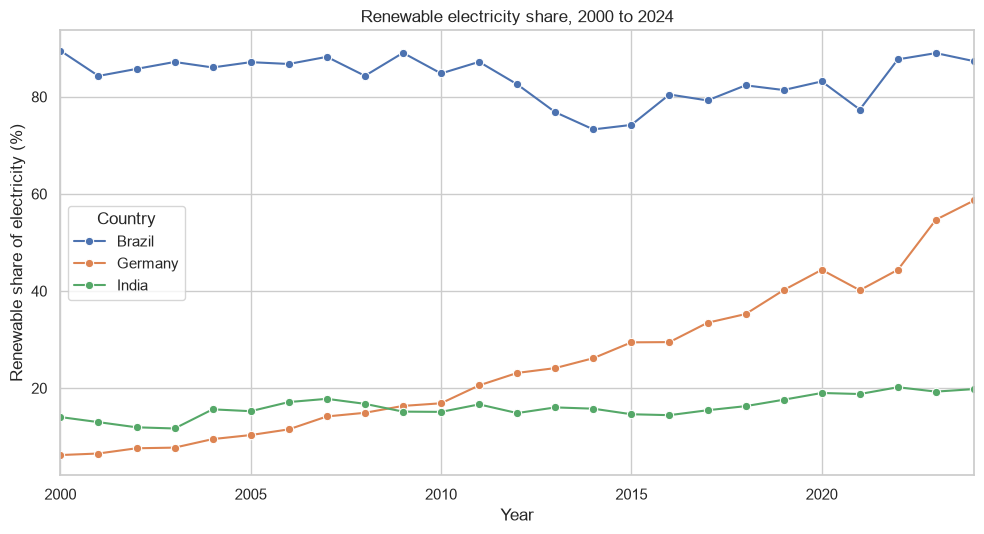

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.lineplot(
    data=analysis_df,
    x="year",
    y="renewables_electricity_share_pct",
    hue="country",
    marker="o",
    ax=ax,
)
ax.set_title("Renewable electricity share, 2000 to 2024")
ax.set_xlabel("Year")
ax.set_ylabel("Renewable share of electricity (%)")
ax.set_xlim(START_YEAR, END_YEAR)
ax.legend(title="Country")
fig.tight_layout()
plt.show()

### Figure 2. Renewable electricity generation

The second chart shows annual generation in terawatt hours. Brazil remains the largest producer in absolute terms. India and Germany both grow substantially over the period, showing why electricity shares and total generation describe different aspects of change.

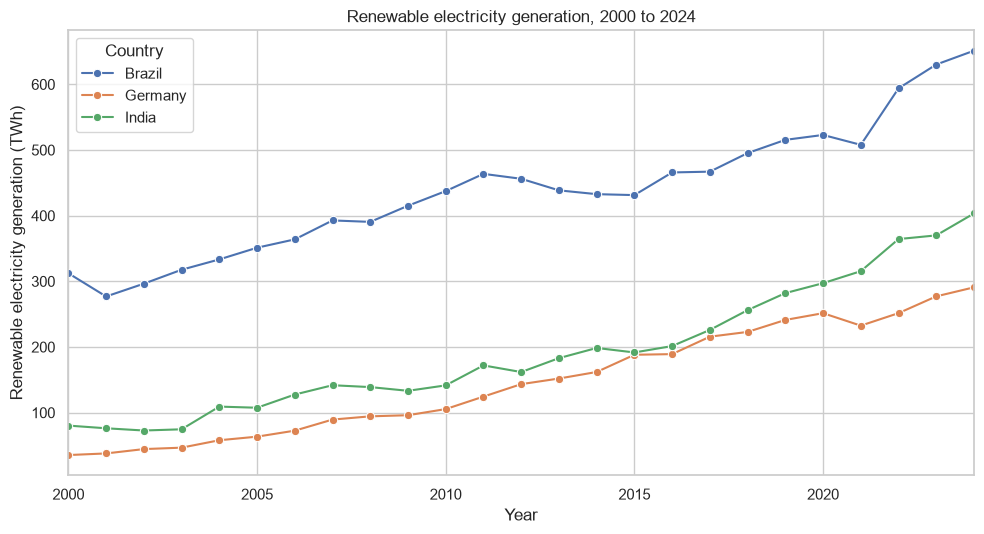

In [6]:
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.lineplot(
    data=analysis_df,
    x="year",
    y="renewables_electricity_twh",
    hue="country",
    marker="o",
    ax=ax,
)
ax.set_title("Renewable electricity generation, 2000 to 2024")
ax.set_xlabel("Year")
ax.set_ylabel("Renewable electricity generation (TWh)")
ax.set_xlim(START_YEAR, END_YEAR)
ax.legend(title="Country")
fig.tight_layout()
plt.show()

### Figure 3. Renewable source mix

The stacked bars compare renewable sources at the start and end of the period. Hydropower remains the largest source in Brazil and India in 2024. Germany's renewable mix is led by wind, with solar also making a visible contribution. The chart uses source shares of total electricity, so the component values can be compared with the overall renewable share.

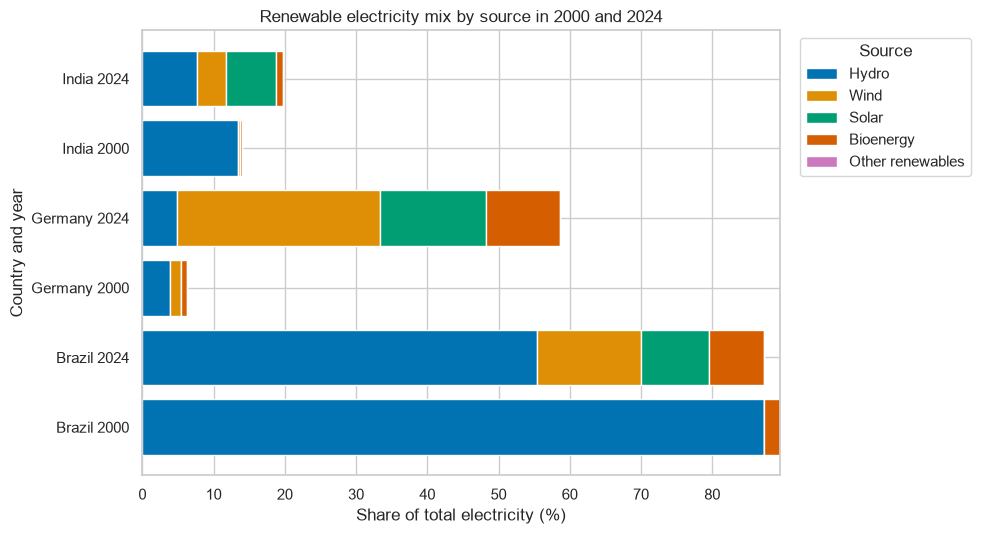

In [7]:
source_columns = {
    "Hydro": "hydro_electricity_share_pct",
    "Wind": "wind_electricity_share_pct",
    "Solar": "solar_electricity_share_pct",
    "Bioenergy": "bioenergy_electricity_share_pct",
    "Other renewables": "other_renewables_excluding_bioenergy_electricity_share_pct",
}
composition = analysis_df.loc[
    analysis_df["year"].isin([START_YEAR, END_YEAR]),
    ["country", "year", *source_columns.values()],
].copy()
composition["country_year"] = composition["country"] + " " + composition["year"].astype(str)
composition = composition.set_index("country_year")

fig, ax = plt.subplots(figsize=(10, 5.5))
left = np.zeros(len(composition))
colors = sns.color_palette("colorblind", n_colors=len(source_columns))
for (label, column), color in zip(source_columns.items(), colors):
    values = composition[column].to_numpy(dtype=float)
    ax.barh(composition.index, values, left=left, label=label, color=color)
    left += values
ax.set_title("Renewable electricity mix by source in 2000 and 2024")
ax.set_xlabel("Share of total electricity (%)")
ax.set_ylabel("Country and year")
ax.legend(title="Source", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()

## Summary

From 2000 to 2024, Germany's renewable electricity share rose from 6.22% to 58.64%, an increase of 52.42 percentage points. India's share rose from 14.05% to 19.81%, while Brazil remained the highest of the three, moving from 89.49% to 87.33%. Generation in terawatt hours increased in all three countries, which shows that a stable or slightly lower share can occur alongside growth in renewable output.

The comparison assumes that the source's country definitions and electricity share measures are consistent across the selected years. The dataset brings together several providers and historical reconstructions, so source methods and revisions can affect the reported series. The analysis is descriptive and does not explain why changes occurred or measure reliability, cost, access, or emissions. The fixed 2000 to 2024 period is a scope decision; 2025 data are available but are not included. One notable pattern is that Brazil's renewable share is high throughout the period, while Germany's much larger share increase is paired with a shift from a hydro light mix toward wind and solar.